# 02 Breast cancer: malignant vs benign
New dataset: change `DATA` and `TARGET`.

## 1. Setup

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare, f_oneway, ttest_rel, wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [2]:
DATA = "data/breast_cancer.csv"
TARGET = "diagnosis"
AVG = "binary"
SCORING = "accuracy"

In [3]:
df = pd.read_csv(DATA)
df.shape

(569, 31)

## 2. EDA

In [4]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [7]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
0


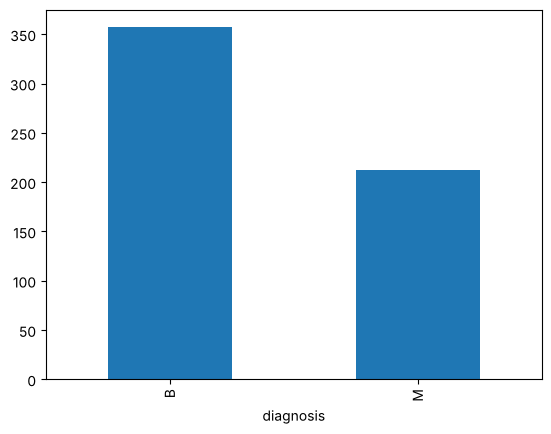

In [8]:
df[TARGET].value_counts().plot(kind="bar")
plt.show()

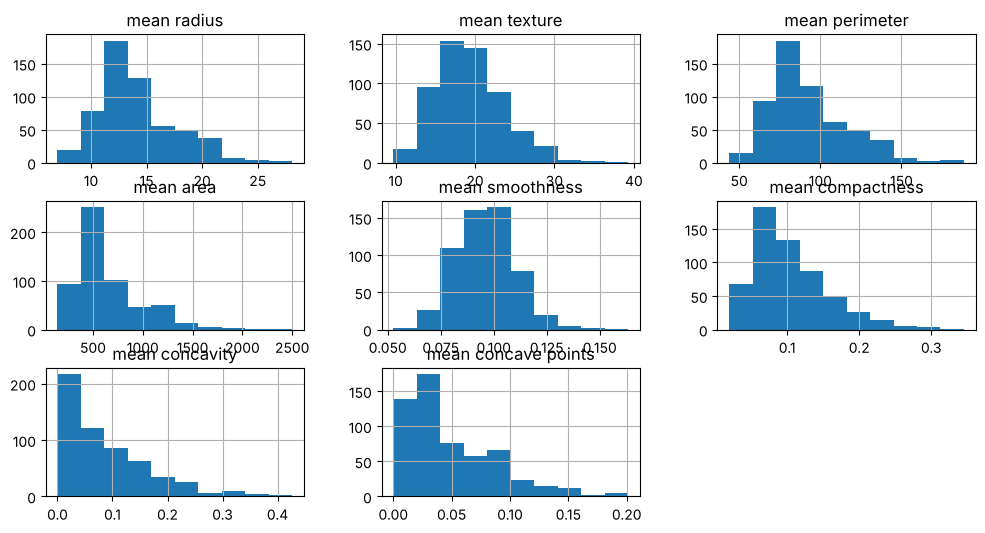

In [9]:
df.select_dtypes("number").iloc[:, :8].hist(figsize=(12, 6))
plt.show()

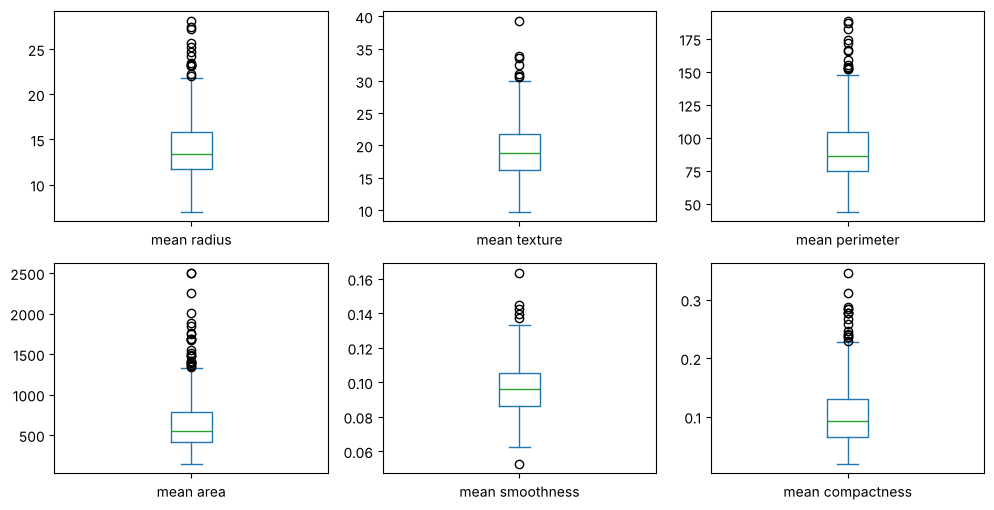

In [10]:
df.select_dtypes("number").iloc[:, :6].plot(
    kind="box", subplots=True, layout=(2, 3), figsize=(12, 6)
)
plt.show()

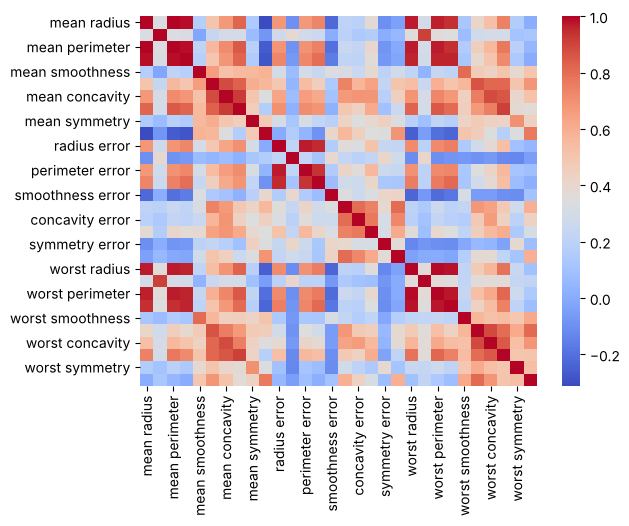

In [11]:
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.show()

## 3. Preprocessing

In [12]:
df = df.drop_duplicates()

In [13]:
for col in df.columns.drop(TARGET):
    if df[col].dtype.kind in "if":
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

In [14]:
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True)

In [15]:
y = LabelEncoder().fit_transform(df[TARGET])
print(np.bincount(y) / len(y))

[0.62741652 0.37258348]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [17]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
def evaluate(model):
    pred = model.predict(X_test)
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred, average=AVG), 4))
    print("Recall   :", round(recall_score(y_test, pred, average=AVG), 4))
    print("F1       :", round(f1_score(y_test, pred, average=AVG), 4))

## 4. Decision Tree

In [19]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
evaluate(dt)

Accuracy : 0.9298
Precision: 0.9048
Recall   : 0.9048
F1       : 0.9048


In [20]:
dt_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"],
}

In [21]:
dt_gs = GridSearchCV(dt, dt_grid, cv=5, scoring=SCORING, n_jobs=-1)
dt_gs.fit(X_train, y_train)
print(dt_gs.best_params_)
print(dt_gs.best_score_)

{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5}
0.9472527472527472


In [22]:
best_dt = dt_gs.best_estimator_
evaluate(best_dt)

Accuracy : 0.9561
Precision: 1.0
Recall   : 0.881
F1       : 0.9367


## 5. Random Forest

In [23]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
evaluate(rf)

Accuracy : 0.9737
Precision: 1.0
Recall   : 0.9286
F1       : 0.963


In [24]:
rf_grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 5, 10],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5],
}

In [25]:
rf_gs = GridSearchCV(rf, rf_grid, cv=5, scoring=SCORING, n_jobs=-1)
rf_gs.fit(X_train, y_train)
print(rf_gs.best_params_)
print(rf_gs.best_score_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 50}
0.9670329670329672


In [26]:
best_rf = rf_gs.best_estimator_
evaluate(best_rf)

Accuracy : 0.9737
Precision: 1.0
Recall   : 0.9286
F1       : 0.963


## 6. AdaBoost

In [27]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)
evaluate(ada)

Accuracy : 0.9825
Precision: 1.0
Recall   : 0.9524
F1       : 0.9756


In [28]:
ada_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 1.0],
}

In [29]:
ada_gs = GridSearchCV(ada, ada_grid, cv=5, scoring=SCORING, n_jobs=-1)
ada_gs.fit(X_train, y_train)
print(ada_gs.best_params_)
print(ada_gs.best_score_)

{'learning_rate': 1.0, 'n_estimators': 200}
0.964835164835165


In [30]:
best_ada = ada_gs.best_estimator_
evaluate(best_ada)

Accuracy : 0.9737
Precision: 1.0
Recall   : 0.9286
F1       : 0.963


## 7. Gradient Boosting

In [31]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
evaluate(gb)

Accuracy : 0.9649
Precision: 1.0
Recall   : 0.9048
F1       : 0.95


In [32]:
gb_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [1, 3, 5],
    "subsample": [0.8, 1.0],
}

In [33]:
gb_gs = GridSearchCV(gb, gb_grid, cv=5, scoring=SCORING, n_jobs=-1)
gb_gs.fit(X_train, y_train)
print(gb_gs.best_params_)
print(gb_gs.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
0.9670329670329672


In [34]:
best_gb = gb_gs.best_estimator_
evaluate(best_gb)

Accuracy : 0.9561
Precision: 1.0
Recall   : 0.881
F1       : 0.9367


## 8. XGBoost

In [35]:
xgb = XGBClassifier(eval_metric="logloss", random_state=42)
xgb.fit(X_train, y_train)
evaluate(xgb)

Accuracy : 0.9649
Precision: 1.0
Recall   : 0.9048
F1       : 0.95


In [36]:
xgb_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

In [37]:
xgb_gs = GridSearchCV(xgb, xgb_grid, cv=5, scoring=SCORING, n_jobs=-1)
xgb_gs.fit(X_train, y_train)
print(xgb_gs.best_params_)
print(xgb_gs.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
0.9714285714285715


In [38]:
best_xgb = xgb_gs.best_estimator_
evaluate(best_xgb)

Accuracy : 0.9649
Precision: 1.0
Recall   : 0.9048
F1       : 0.95


## 9. Grid Search vs Random Search

In [39]:
start = time.time()
grid_search = GridSearchCV(dt, dt_grid, cv=5, scoring=SCORING)
grid_search.fit(X_train, y_train)
grid_time = time.time() - start

In [40]:
start = time.time()
random_search = RandomizedSearchCV(
    dt,
    dt_grid,
    n_iter=10,
    cv=5,
    scoring=SCORING,
    random_state=42,
)
random_search.fit(X_train, y_train)
random_time = time.time() - start

In [41]:
print("Grid combinations:", len(grid_search.cv_results_["params"]))
print("Grid best score:", round(grid_search.best_score_, 4))
print("Grid time:", round(grid_time, 2))
print("Random combinations:", len(random_search.cv_results_["params"]))
print("Random best score:", round(random_search.best_score_, 4))
print("Random time:", round(random_time, 2))

Grid combinations: 90
Grid best score: 0.9473
Grid time: 2.62
Random combinations: 10
Random best score: 0.9363
Random time: 0.33


In [42]:
results = pd.DataFrame(grid_search.cv_results_)
fold_cols = [c for c in results.columns if c.startswith("split")]
print(results.loc[grid_search.best_index_, fold_cols])

split0_test_score    0.967033
split1_test_score    0.967033
split2_test_score    0.934066
split3_test_score    0.956044
split4_test_score    0.912088
Name: 49, dtype: float64


## 10. 5-fold Cross-Validation

In [43]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [44]:
models = {
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "AdaBoost": best_ada,
    "Gradient Boosting": best_gb,
    "XGBoost": best_xgb,
}

In [45]:
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv5, scoring=SCORING)
    print(
        name,
        s.round(3),
        "mean:",
        round(s.mean(), 4),
        "std:",
        round(s.std(), 4),
    )

Decision Tree [0.901 0.967 0.923 0.912 0.945] mean: 0.9297 std: 0.0237


Random Forest [0.956 0.989 0.934 0.945 0.978] mean: 0.9604 std: 0.0204


AdaBoost [0.978 0.978 0.945 0.967 0.989] mean: 0.9714 std: 0.0149


Gradient Boosting [0.967 0.978 0.956 0.956 0.989] mean: 0.9692 std: 0.0128


XGBoost [0.967 0.967 0.967 0.967 0.989] mean: 0.9714 std: 0.0088


## 11. PCA vs No PCA

In [46]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(X_train.shape[1], "->", pca.n_components_)

30 -> 10


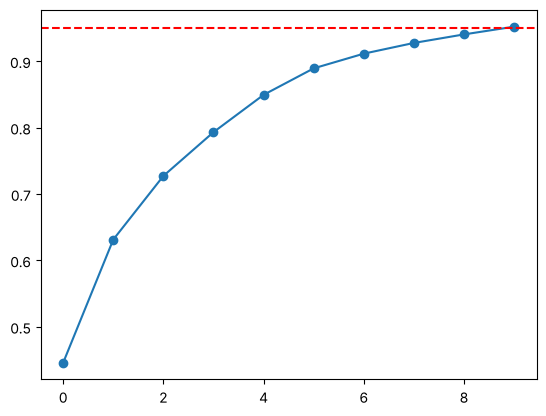

In [47]:
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.show()

In [48]:
for name, model in models.items():
    no_pca = cross_val_score(
        model, X_train, y_train, cv=cv5, scoring=SCORING
    ).mean()
    with_pca = cross_val_score(
        model, X_train_pca, y_train, cv=cv5, scoring=SCORING
    ).mean()
    print(name, "| no PCA:", round(no_pca, 4), "| PCA:", round(with_pca, 4))

Decision Tree | no PCA: 0.9297 | PCA: 0.9429


Random Forest | no PCA: 0.9604 | PCA: 0.9604


AdaBoost | no PCA: 0.9714 | PCA: 0.9604


Gradient Boosting | no PCA: 0.9692 | PCA: 0.956


XGBoost | no PCA: 0.9714 | PCA: 0.9604


## 12. Statistical Significance

In [49]:
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

In [50]:
scores = {}
for name, model in models.items():
    scores[name] = cross_val_score(
        model, X_train, y_train, cv=repeated_cv, scoring=SCORING
    )
model_names = list(scores)
model_scores = list(scores.values())
print(pd.DataFrame(scores).mean().round(4))

Decision Tree        0.9355
Random Forest        0.9582
AdaBoost             0.9729
Gradient Boosting    0.9619
XGBoost              0.9692
dtype: float64


In [51]:
print("Friedman p:", friedmanchisquare(*model_scores)[1])
print("ANOVA p:", f_oneway(*model_scores)[1])

Friedman p: 3.8678454241894365e-06
ANOVA p: 0.0001971924753595788


In [52]:
means = [s.mean() for s in model_scores]
best = int(np.argmax(means))
print("Best model:", model_names[best])

Best model: AdaBoost


In [53]:
alpha = 0.05 / (len(model_names) - 1)
for i in range(len(model_names)):
    if i == best:
        continue
    t_p = ttest_rel(model_scores[best], model_scores[i])[1]
    w_p = wilcoxon(model_scores[best], model_scores[i])[1]
    print(model_names[best], "vs", model_names[i])
    print("t-test p:", round(t_p, 4))
    print("wilcoxon p:", round(w_p, 4))
    print("significant:", max(t_p, w_p) < alpha)

AdaBoost vs Decision Tree
t-test p: 0.0
wilcoxon p: 0.0006
significant: True
AdaBoost vs Random Forest
t-test p: 0.0314
wilcoxon p: 0.0297
significant: False
AdaBoost vs Gradient Boosting
t-test p: 0.0596
wilcoxon p: 0.0486
significant: False
AdaBoost vs XGBoost
t-test p: 0.2905
wilcoxon p: 0.3713
significant: False


## 13. Class Imbalance

In [54]:
print(pd.Series(y_train).value_counts(normalize=True))

0    0.626374
1    0.373626
Name: proportion, dtype: float64


In [55]:
small = np.bincount(y_train).argmin()
big = np.bincount(y_train).argmax()
X_small = X_train[y_train == small]
X_big = X_train[y_train == big]

In [56]:
X_small_up = resample(
    X_small, replace=True, n_samples=len(X_big), random_state=42
)
X_over = np.vstack([X_big, X_small_up])
y_over = np.array([big] * len(X_big) + [small] * len(X_big))

In [57]:
X_big_down = resample(
    X_big, replace=False, n_samples=len(X_small), random_state=42
)
X_under = np.vstack([X_big_down, X_small])
y_under = np.array([big] * len(X_small) + [small] * len(X_small))

In [58]:
setups = {
    "original": (DecisionTreeClassifier(random_state=42), X_train, y_train),
    "class_weight": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        X_train,
        y_train,
    ),
    "oversample": (DecisionTreeClassifier(random_state=42), X_over, y_over),
    "undersample": (DecisionTreeClassifier(random_state=42), X_under, y_under),
}

In [59]:
for name, (model, X_fit, y_fit) in setups.items():
    pred = model.fit(X_fit, y_fit).predict(X_test)
    print(name)
    print("accuracy:", round(accuracy_score(y_test, pred), 4))
    print("recall:", round(recall_score(y_test, pred, average=AVG), 4))
    print("f1:", round(f1_score(y_test, pred, average=AVG), 4))

original
accuracy: 0.9298
recall: 0.9048
f1: 0.9048
class_weight
accuracy: 0.9035
recall: 0.8333
f1: 0.8642
oversample
accuracy: 0.9386
recall: 0.8571
f1: 0.9114
undersample
accuracy: 0.886
recall: 0.881
f1: 0.8506


## 14. Final Evaluation

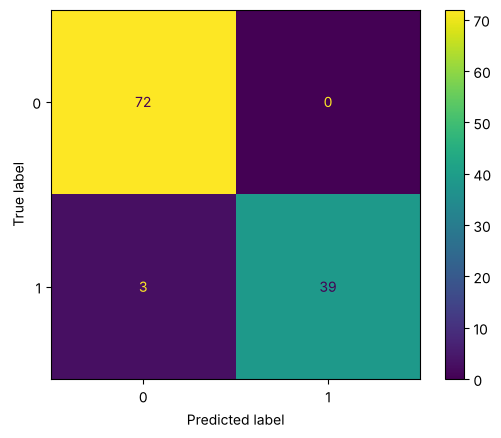

In [60]:
best_model = models[model_names[best]]
pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

ROC AUC: 0.9871


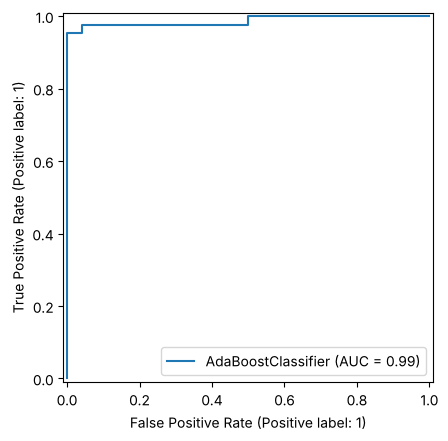

In [61]:
roc = RocCurveDisplay.from_estimator(best_model, X_test, y_test)
print("ROC AUC:", round(roc.roc_auc, 4))
plt.show()